<a href="https://colab.research.google.com/github/ThiagoPoppe/lamir2026-summer-code/blob/main/fingerprinting_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬️ Audio Fingerprinting Experiments: Analyzing Fingerprint Robustness to Audio Degradation

This notebook explores the robustness of the fingerprinting algorithm against different audio modifications using [GTZAN](https://www.cs.cmu.edu/~gtzan/work/pubs/tsap02gtzan.pdf), a well-known dataset in the field of Music Information Retrieval (MIR).

Although this dataset was not originally designed for audio fingerprinting, but rather for music genre classification, it serves as a useful resource, providing 30-second audio samples from different music genres. This allows us to conduct experiments aimed at investigating the limitations of the fingerprinting algorithm proposed by [Wang em 2003](https://www.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf).

In [1]:
# If running on Google Colab, uncomment and run the following lines.

# !git clone https://github.com/ThiagoPoppe/lamir2026-summer-code.git
# %cd lamir2026-summer-code
# %pip install -q -r requirements.txt

# from google.colab import output
# output.enable_custom_widget_manager()

In [2]:
import os
import random
import librosa

import numpy as np
import ipywidgets as widgets
import IPython.display as ipd
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm
from collections import defaultdict

from audiomentations import (
    Compose,
    PitchShift,
    TimeStretch,
    BandPassFilter,
    ClippingDistortion,
    Mp3Compression,
    AddGaussianSNR
)

from source.data import gtzan_download, build_catalog_dataframe
from source.fingerprint import (
    load_audio,
    compute_spectral_feature,
    compute_constellation_map,
    compute_hashes,
    find_match
)

from source.visualization.gtzan import song_selector

## 1. The GTZAN Dataset

Created by [George Tzanetakis (2002)](https://www.cs.cmu.edu/~gtzan/work/pubs/tsap02gtzan.pdf), the GTZAN dataset is widely used to evaluate music genre classification systems. Therefore, the dataset contains 1000 clips, of 30 seconds each, equally distributed across 10 music genres.

Run the next cell to download this dataset.



In [3]:
dataset_path, audio_dir = gtzan_download(output_dir='./gtzan_dataset')

In [4]:
print('Dataset downloaded to:', dataset_path)
print('Audio files are in:', audio_dir)

Dataset downloaded to: ./gtzan_dataset
Audio files are in: ./gtzan_dataset/Data/genres_original


Run the next cell to build a catalog, represented as a Pandas DataFrame. You can use it throughout the notebook to easily fetch songs by genre and artist.

> **Note**$^\textbf{1}$: The original GTZAN dataset doesn't specify the name of the songs or the associated artists. Therefore, [Bob L. Sturm's GitHub repository](https://github.com/boblsturm/GTZAN/tree/main) is also used to add this metadata to the GTZAN entries.

> **Note**$^\textbf{2}$: The entry `jazz.00054.wav` appears to be corrupted. So the built catalog already discards this entry from the DataFrame, that's why the final catalog has 999 entries instead of 1000.

In [5]:
catalog_df = build_catalog_dataframe(audio_dir=audio_dir)

In [6]:
print(f"Total valid tracks indexed: {len(catalog_df)}")
catalog_df

Total valid tracks indexed: 999


,track_id,filename,genre,artist,title,display_name,filepath
0,blues.00000,blues.00000.wav,blues,John Lee Hooker,"One Bourbon, One Scotch And One Beer","John Lee Hooker - One Bourbon, One Scotch And ...",./gtzan_dataset/Data/genres_original/blues/blu...
1,blues.00001,blues.00001.wav,blues,John Lee Hooker,I'm In The Mood For Love,John Lee Hooker - I'm In The Mood For Love,./gtzan_dataset/Data/genres_original/blues/blu...
2,blues.00002,blues.00002.wav,blues,John Lee Hooker,Think Twice Before You Go,John Lee Hooker - Think Twice Before You Go,./gtzan_dataset/Data/genres_original/blues/blu...
3,blues.00003,blues.00003.wav,blues,John Lee Hooker,I'm Bad Like Jesse James,John Lee Hooker - I'm Bad Like Jesse James,./gtzan_dataset/Data/genres_original/blues/blu...
4,blues.00004,blues.00004.wav,blues,John Lee Hooker,Walkin' the Boogie,John Lee Hooker - Walkin' the Boogie,./gtzan_dataset/Data/genres_original/blues/blu...
...,...,...,...,...,...,...,...
994,rock.00095,rock.00095.wav,rock,The Stone Roses,Bye Bye Bad Man,The Stone Roses - Bye Bye Bad Man,./gtzan_dataset/Data/genres_original/rock/rock...
995,rock.00096,rock.00096.wav,rock,The Stone Roses,(Song For My) Sugar Spun Sister,The Stone Roses - (Song For My) Sugar Spun Sister,./gtzan_dataset/Data/genres_original/rock/rock...
996,rock.00097,rock.00097.wav,rock,The Stone Roses,Made Of Stone,The Stone Roses - Made Of Stone,./gtzan_dataset/Data/genres_original/rock/rock...
997,rock.00098,rock.00098.wav,rock,The Stone Roses,Shoot You Down,The Stone Roses - Shoot You Down,./gtzan_dataset/Data/genres_original/rock/rock...


In the next cell we present a simple interactive plot that shows the top 10 artists distribution per genre.

In [7]:
def plot_top10_artists_per_genre(genre: str):
    if genre == 'All':
        top10_artists = catalog_df['artist'].value_counts().head(10)
    else:
        genre_catalog_df = catalog_df[catalog_df.genre == genre]
        top10_artists = genre_catalog_df['artist'].value_counts().head(10)

    plt.title(f'Top 10 most common artists in the "{genre}" genre')
    plt.barh(top10_artists.index, top10_artists.values)
    plt.xlabel('Number of songs')
    plt.ylabel('Artist')
    plt.show()

possible_genres = ['All'] + sorted(catalog_df.genre.unique())
widgets.interact(
    plot_top10_artists_per_genre,
    genre=widgets.Dropdown(options=possible_genres, description='Genre')   
)

interactive(children=(Dropdown(description='Genre', options=('All', 'blues', 'classical', 'country', 'disco', …

<function __main__.plot_top10_artists_per_genre(genre: str)>

And here you can interactivly filter the catalog by a specific artist and choose to hear one of its entries.

Try to hear the entry of _Bohemian Rhapsody_ by Queen, for example.

In [8]:
song_selector(catalog_df=catalog_df)

> In case you are interested in a deeper analysis of the GTZAN dataset, reading the article by [Bob L. Sturm (2024)](https://arxiv.org/pdf/1306.1461) is strongly recommended.

## 2. Useful functions for this notebook

To focus this notebook only on the experiments themselves, we provide a collection of useful functions that will help you guide your own experiments and draw your own conclusions. 

In the next cells, we explain how each one operates.

#### 2.1. Loading audios

In order to load an audio, you can use the `load_audio` function.

You can read the documentation for this function by running the next cell.

In [9]:
help(load_audio)

Help on function load_audio in module source.fingerprint:

load_audio(filepath: str, sr: int = None, start: float = 0.0, duration: float = None) -> tuple[numpy.ndarray, int]
    Load an audio file as a mono waveform.

    Parameters
    ----------
    filepath : str
        Path to the audio file. Any format supported by librosa/soundfile
        or audioread can be used.
    sr : int, optional (default = None)
        Target sample rate to resample the audio. If None, the native sample rate is used.
    start : float, optional (default = 0.0)
        Time offset in seconds to start loading the audio. Must be between 0 and 30 seconds.
    duration : float, optional (default = None)
        Duration of the audio to load in seconds. Start + duration must not exceed 30 seconds.
        If None, the whole audio starting from `start` is loaded.

    Returns
    -------
    wave : np.ndarray, shape (n_samples,)
        Mono waveform, as floating-point values in [-1, 1].
    sr : int
        

By default, as shown in the cell below, the entire audio track is loaded with its native sampling rate (which for GTZAN audios is set to 22050 Hz).

In [10]:
dancing_queen_track_filepath = os.path.join(audio_dir, 'disco/disco.00067.wav')  # Dancing Queen - ABBA
wave, sr = load_audio(dancing_queen_track_filepath)

print('Loaded sampling rate:', sr)
ipd.display(ipd.Audio(wave, rate=sr))

Loaded sampling rate: 22050


You can customize its loading sampling rate by changing the `sr` parameter.

> Notice that when set to a lower sampling rate, the resulting audio seems to have less quality.

In [12]:
wave, sr = load_audio(dancing_queen_track_filepath, sr=8000)

print('Loaded sampling rate:', sr)
ipd.display(ipd.Audio(wave, rate=sr))

Loaded sampling rate: 8000


Finally, you can also customize its starting and duration parameters. In the next cell, for instance, we start at 15 seconds and load only 5 seconds of the audio.

> Notice that both `start` and `duration` parameters must be positive and `start + duration` cannot exceed 30 seconds, given that GTZAN audio tracks are limited by this duration.

In [13]:
wave, sr = load_audio(dancing_queen_track_filepath, start=15, duration=5)

print('Loaded sampling rate:', sr)
ipd.display(ipd.Audio(wave, rate=sr))

Loaded sampling rate: 22050


#### 2.2. Computing spectral features

In order to compute the spectral feature used for the audio fingerprinting algorithm, you can use the `compute_spectral_feature` function.

You can read the documentation for this function by running the next cell.

In [14]:
help(compute_spectral_feature)

Help on function compute_spectral_feature in module source.fingerprint:

compute_spectral_feature(wave: numpy.ndarray, sr: int, kind: str = 'stft') -> numpy.ndarray
    Compute a non-negative time-frequency representation of a waveform.

    Parameters
    ----------
    wave : np.ndarray, shape (n_samples,)
        Mono waveform.
    sr : int
        Sample rate of `wave` in Hz.
    kind : {'stft', 'cqt', 'chroma'}, optional (default = 'stft')
        Type of representation to compute.
        - 'stft': magnitude of the Short-Time Fourier Transform, with linear
          frequency resolution. Only the first 128 frequency bins are used.
        - 'cqt': magnitude of the Constant-Q Transform, with logarithmic
          frequency resolution of one bin per semitone, starting at C1
          (~32.7 Hz), having 7 octaves (84 bins) by default.
        - 'chroma': 12-bin pitch-class profile (one bin per semitone, octaves
          folded together), computed from the STFT.

    Returns
    ---

Notice that, differently from the [explanation notebook](./audio_fingerprinting.ipynb), this function allows the computation of other spectral features beside STFT, such as the CQT (Constant-Q Transform) and Chromagram through the `kind` parameter. It will be an experiment to switch the spectral feature and see how the audio fingerpriting algorithm retrieval behaves. A brief explanation of these other representations, alongside their computation using this function are presented in the next cell where we compute these features for the track `disco.00067`, which represents the song _Dancing Queen_ by ABBA.

In [15]:
wave, sr = load_audio(dancing_queen_track_filepath)

print('Loaded sampling rate:', sr)
ipd.display(ipd.Audio(wave, rate=sr))

Loaded sampling rate: 22050


In [16]:
stft = compute_spectral_feature(wave, sr, kind='stft')
print('STFT spectral feature shape:', stft.shape)

cqt = compute_spectral_feature(wave, sr, kind='cqt')
print('Constant-Q Transform (CQT) spectral feature shape:', cqt.shape)

chroma = compute_spectral_feature(wave, sr, kind='chroma')
print('Chromagram spectral feature shape:', chroma.shape)

STFT spectral feature shape: (128, 1293)
Constant-Q Transform (CQT) spectral feature shape: (84, 1293)
Chromagram spectral feature shape: (12, 1293)


As seen in the above cell, all features share the same time dimension, meaning that they have the same number of frames. The main difference between them relies on the frequency axis.

While the STFT represents the frequency axis as <insert brief explanation here...>, the Constant-Q representation <insert brief explanation here...>, and the Chromagram goes a step further by grouping each frequency associated with the 12 pitch classes, i.e., the 12 musical notes despite their octave, meaning that the same $\texttt{C}$ note, regardless of octave, will have its activation shown in this representation, going from 0 (no activation) to 1 (maximum activation possible).

In the next cell, we present a simple plot that visually displays each spectral feature.

> It is important to remember that the STFT spectral feature actually has way more than 128 frequency bins. For our purposes we only kept the first 128 frequency bins as explained in the [explanation notebook](./audio_fingerprinting.ipynb).

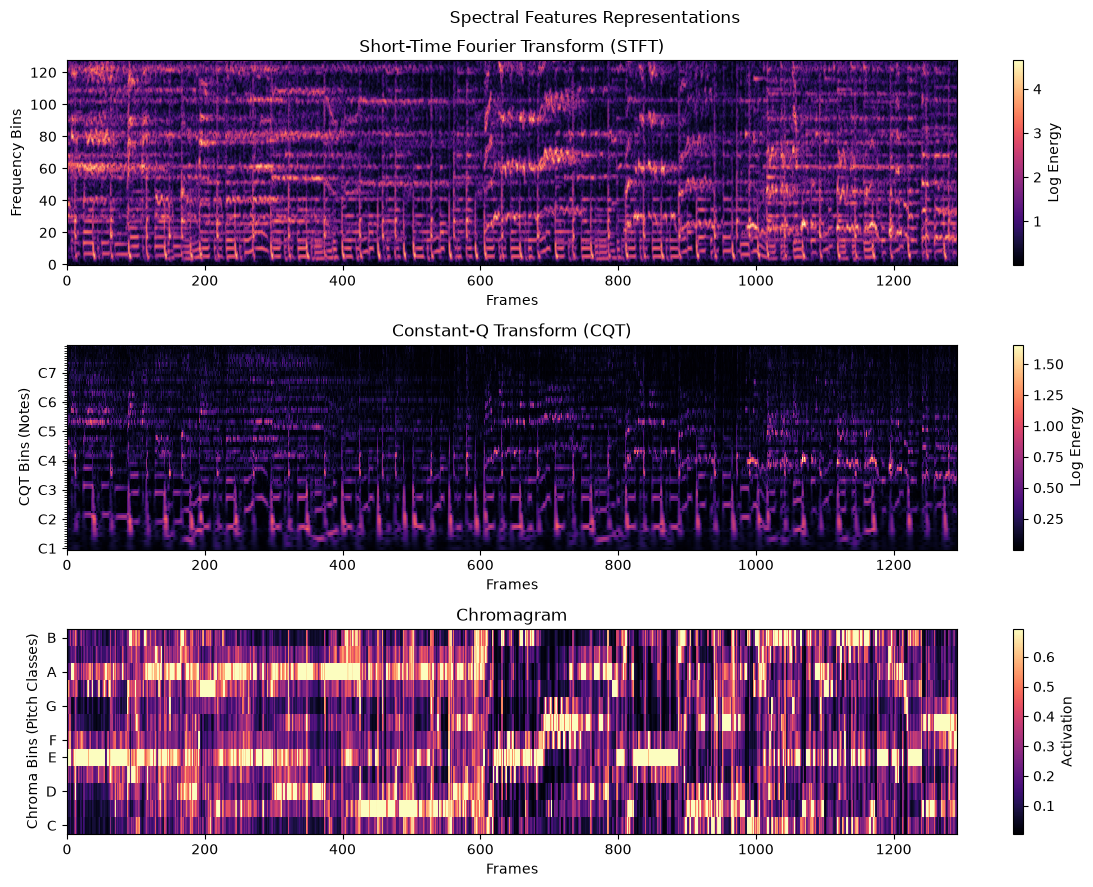

In [17]:
fig, axs = plt.subplots(3, 1, figsize=(12, 9))

fig.suptitle('Spectral Features Representations')

axs[0].set_title('Short-Time Fourier Transform (STFT)')
img = axs[0].imshow(np.log1p(stft), cmap='magma', origin='lower', aspect='auto')
axs[0].set_xlabel('Frames')
axs[0].set_ylabel('Frequency Bins')
fig.colorbar(img, ax=axs[0], label='Log Energy')

axs[1].set_title('Constant-Q Transform (CQT)')
img = librosa.display.specshow(np.log1p(cqt), sr=sr, x_axis='frames', y_axis='cqt_note', ax=axs[1])
axs[1].set_ylabel('CQT Bins (Notes)')
fig.colorbar(img, ax=axs[1], label='Log Energy')

axs[2].set_title('Chromagram')
img = librosa.display.specshow(np.log1p(chroma), sr=sr, x_axis='frames', y_axis='chroma', ax=axs[2])
axs[2].set_ylabel('Chroma Bins (Pitch Classes)')
fig.colorbar(img, ax=axs[2], label='Activation')

fig.tight_layout()

#### 2.3. Building constellation maps

In order to compute a constellation map given a spectral feature, you can use the `compute_constellation_map` function.

You can read the documentation for this function by running the next cell.

> Notice that the default parameters were set considering an STFT representation and may not be the most suitable parameters for the other spectral representations (it will part of a different experiment to thinker with these parameters and see how different they are depending on which spectral feature you choose to work with).

In [18]:
help(compute_constellation_map)

Help on function compute_constellation_map in module source.fingerprint:

compute_constellation_map(spectral_feature: numpy.ndarray, freq_neighborhood: int = 11, time_neighborhood: int = 5, threshold: float = 0.01) -> numpy.ndarray
    Find the local maxima of a spectral feature that make up the constellation map.

    A point is a peak if it is the maximum of its local window (of size
    `freq_neighborhood` x `time_neighborhood`) and its magnitude is above
    `threshold`.

    Parameters
    ----------
    spectral_feature : np.ndarray, shape (n_freq_bins, n_frames)
        Non-negative time-frequency representation, e.g. the output of
        `compute_spectral_feature`.
    freq_neighborhood : int, optional (default = 11)
        Height of the local window, in frequency bins (centered on the point,
        so a value of 11 looks 5 bins up and 5 bins down). Should be odd.
    time_neighborhood : int, optional (default = 5)
        Width of the local window, in time frames (centered 

For this usage example we will use the pre-computed STFT for the song _Dancing Queen_ by ABBA and use the default parameters to build its constellation map.

In [19]:
constellation_map = compute_constellation_map(stft)
print('Constellation map shape:', constellation_map.shape)

Constellation map shape: (128, 1293)


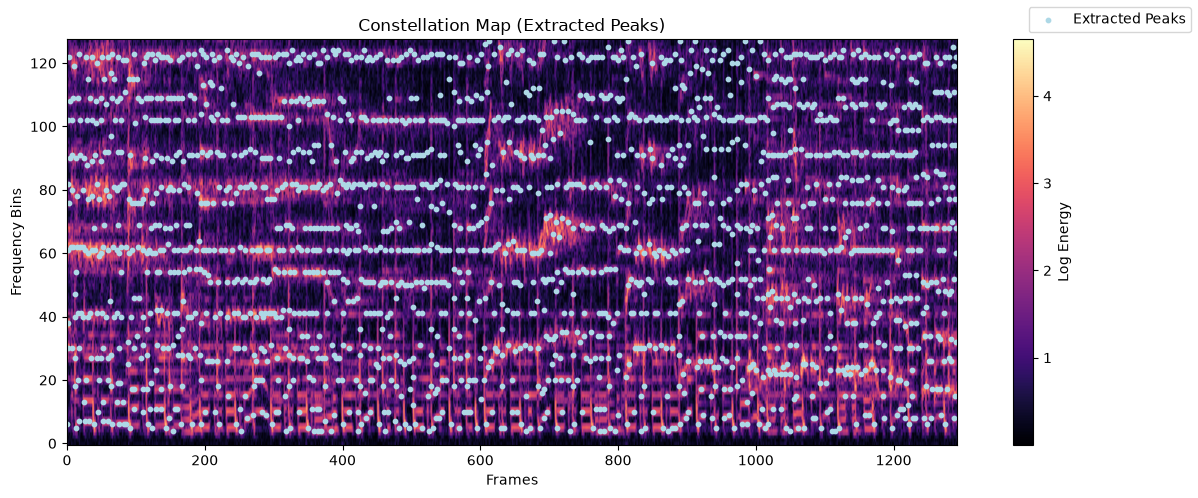

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title('Constellation Map (Extracted Peaks)')

img = ax.imshow(np.log1p(stft), cmap='magma', origin='lower', aspect='auto')

peaks = np.where(constellation_map)
ax.scatter(peaks[1], peaks[0], color='lightblue', marker='o', s=10, label='Extracted Peaks')

ax.set_xlabel('Frames')
ax.set_ylabel('Frequency Bins')

fig.legend()
fig.colorbar(img, ax=ax, label='Log Energy')
fig.tight_layout()
plt.show()

#### 2.4. Hashing and finding a query match

In order to perform the final steps of our audio fingerprinting algorithm, i.e., the combinatorial hashing and subsequent query matching, you can use the `compute_hashes` and `find_match` functions.

You can read the documentation for these functions by running the next cells.

> Notice that the default parameters were set considering an STFT representation and may not be the most suitable parameters for the other spectral representations (it will part of a different experiment to thinker with these parameters and see how different they are depending on which spectral feature you choose to work with).

In [21]:
help(compute_hashes)

Help on function compute_hashes in module source.fingerprint:

compute_hashes(constellation_map: numpy.ndarray, sr: int, metadata: Optional[dict[str, Any]] = None, target_zone_freq_size: int = 31, target_zone_time_size: int = 19, target_zone_time_delay: int = 20) -> dict[str, list[dict[str, typing.Any]]]
    Generate fingerprint hashes from a constellation map using anchor-target pairs.

    Every peak in the constellation map is treated as an anchor. For each anchor,
    a rectangular target zone is defined in the time-frequency plane, centered
    `target_zone_time_delay` frames after the anchor in time and on the anchor's
    frequency bin. Each peak that falls inside this zone is paired with the
    anchor to form a hash of the form ``"{anchor_freq}_{target_freq}_{timedelta}"``.

    Parameters
    ----------
    constellation_map : numpy.ndarray
        Boolean 2D array of shape ``(num_freq_bins, num_time_frames)``, where
        True marks a constellation peak.
    sr : int
     

In [22]:
help(find_match)

Help on function find_match in module source.fingerprint:

find_match(query_hashes: dict[str, list[dict]], db_hashes: dict[str, list[dict]]) -> tuple[str, float, int]
    Find the best match for a query constellation map in the database.

    Parameters
    ----------
    query_hashes : np.ndarray
        The hashes of the query audio.
    db_hashes : dict[str, list[dict]]
        The hashes of the database.

    Returns
    -------
    matched_song : str
        The name of the matched song.
    matched_offset : float
        The offset of the match in seconds.
    counter : int
        The number of matching peaks.



In order to provide a functional example of these functions, we will perform a simple matching of a random clip of the _Dancing Queen_ entry against the constellation maps calculated for all disco musics in the database.

> **Pro tip:** use this code as a skeleton for subsequent experiments to reduce the analysis to a certain genre if wanted.

In [23]:
# Slicing the DataFrame to get only disco tracks
disco_catalog_df = catalog_df[catalog_df['genre'] == 'disco']
disco_catalog_df

,track_id,filename,genre,artist,title,display_name,filepath
300,disco.00000,disco.00000.wav,disco,Boz Scaggs,Lowdown,Boz Scaggs - Lowdown,./gtzan_dataset/Data/genres_original/disco/dis...
301,disco.00001,disco.00001.wav,disco,Gloria Gaynor,I Will Survive,Gloria Gaynor - I Will Survive,./gtzan_dataset/Data/genres_original/disco/dis...
302,disco.00002,disco.00002.wav,disco,Archie Bell and The Drells,Look Back Over Your Shoulder,Archie Bell and The Drells - Look Back Over Yo...,./gtzan_dataset/Data/genres_original/disco/dis...
303,disco.00003,disco.00003.wav,disco,Don Armando,Deputy of Love,Don Armando - Deputy of Love,./gtzan_dataset/Data/genres_original/disco/dis...
304,disco.00004,disco.00004.wav,disco,Carl Douglas,Run Back,Carl Douglas - Run Back,./gtzan_dataset/Data/genres_original/disco/dis...
...,...,...,...,...,...,...,...
395,disco.00095,disco.00095.wav,disco,Donna Summer,Bad Girls,Donna Summer - Bad Girls,./gtzan_dataset/Data/genres_original/disco/dis...
396,disco.00096,disco.00096.wav,disco,Shirley & Company,"Shame, Shame, Shame","Shirley & Company - Shame, Shame, Shame",./gtzan_dataset/Data/genres_original/disco/dis...
397,disco.00097,disco.00097.wav,disco,Patrick Cowley; Sylvester,Do You Wanna Funk?,Patrick Cowley; Sylvester - Do You Wanna Funk?,./gtzan_dataset/Data/genres_original/disco/dis...
398,disco.00098,disco.00098.wav,disco,Boney M.,Rasputin,Boney M. - Rasputin,./gtzan_dataset/Data/genres_original/disco/dis...


In [24]:
# Loading the whole tracks and computing their hashes, therefore creating our hashes database
db_hashes = defaultdict(list)

for row in tqdm(disco_catalog_df.itertuples(), total=len(disco_catalog_df)):  # tqdm is used to display a progress bar over the iterations
    wave, sr = load_audio(row.filepath)
    stft = compute_spectral_feature(wave, sr, kind='stft')
    constellation_map = compute_constellation_map(stft)

    metadata = {'track_id': row.track_id}
    hashes = compute_hashes(constellation_map, sr=sr, metadata=metadata)

    for hash_id, values in hashes.items():
        db_hashes[hash_id].extend(values)

  0%|          | 0/100 [00:00<?, ?it/s]

In [63]:
# Loading a random 5 seconds section of the track to serve as a query
random_start = random.uniform(0, 25)  # choosing a random start from 0 to 25 seconds so that the query has at least 5 seconds
wave, sr = load_audio(dancing_queen_track_filepath, start=random_start)

print(f'Random start offset: {random_start:.2f} seconds')
ipd.display(ipd.Audio(wave, rate=sr))

Random start offset: 5.57 seconds


In [64]:
# Performing the query match procedure (it is important to use the same parameters as the one that generated the database hashes)
stft = compute_spectral_feature(wave, sr=sr, kind='stft')
constellation_map = compute_constellation_map(stft)
hashes = compute_hashes(constellation_map, sr=sr)

matched_track_id, matched_offset, counter = find_match(hashes, db_hashes)
track_info = catalog_df[catalog_df['track_id'] == matched_track_id]

print('Matched track id:', matched_track_id)
print('Matched song artist:', track_info['artist'].item())
print('Matched song title:', track_info['title'].item())
print('Matched song genre:', track_info['genre'].item())
print('Matched offset in seconds:', matched_offset)
print('Number of matched peaks:', counter)

Matched track id: disco.00067
Matched song artist: ABBA
Matched song title: Dancing Queen
Matched song genre: disco
Matched offset in seconds: 5.57
Number of matched peaks: 7336


## 3. Experiments

### 3.1. Measuring Fingerprint Accuracy

In [70]:
## Create function to report the parameter configuration accuracy ##

#### 3.1.1. Query Size Impact

#### 3.1.2. Spectral Feature Impact

### 3.2. Measuring Fingerprint Robustness

In [69]:
## Create function to report the percentage of peaks that were preserved ##

#### 3.2.1 Audio Degradation Impact

So far, we have only extracted the fingerprint of a pristine, well-behaved audio track. However, real-world queries, like the ones received by Shazam, are rarely perfect. This was especially true back in 2003 when the paper was published. At that time, the algorithm had to accurately identify songs recorded in noisy bars, captured through primitive flip-phone microphones, and heavily compressed over 2G cellular networks.

To test the robustness of our constellation maps, we will artificially degrade our audio query to simulate an early 2000s mobile phone recording. We will use the [audiomentations](https://github.com/iver56/audiomentations) Python library, which makes it easy to apply realistic audio distortions.

In [ ]:
zearly_mobile_pipeline = Compose([
    # 1. Simulate the narrow frequency band of old 2G cellular networks
    BandPassFilter(min_center_freq=1500.0, max_center_freq=2000.0, min_bandwidth_fraction=1.0, max_bandwidth_fraction=1.5, p=1.0),

    # 2. Apply heavy digital compression (early GSM networks were ~13 kbps)
    Mp3Compression(min_bitrate=8, max_bitrate=32, backend="fast-mp3-augment", p=1.0),

    # 3. Simulate a cheap microphone clipping
    ClippingDistortion(min_percentile_threshold=1, max_percentile_threshold=5, p=1.0),

    # 4. Add proportional static hiss (using SNR ensures it scales with track volume)
    AddGaussianSNR(min_snr_db=10.0, max_snr_db=15.0, p=1.0)
])

In [ ]:
print('Original Waveform')
ipd.display(ipd.Audio(data=wave, rate=sr))

print('Artificially Degraded Waveform')
degraded_wave = early_mobile_pipeline(samples=wave, sample_rate=sr)
ipd.display(ipd.Audio(data=degraded_wave, rate=sr))

In [ ]:
degraded_stft = np.abs(librosa.stft(degraded_wave))[:128, :]
degraded_constellation_map = create_constellation_map(degraded_stft)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title('Constellation Map Robustness: Original vs. Artifically Degraded Recording')

img = ax.imshow(np.log1p(filtered_stft_mag), cmap='magma', origin='lower', aspect='auto')

original_peaks = np.where(constellation_map)
ax.scatter(original_peaks[1], original_peaks[0], color='red', marker='o', s=15, label='Original Peaks')

degraded_peaks = np.where(degraded_constellation_map)
ax.scatter(degraded_peaks[1], degraded_peaks[0], color='lightblue', marker='o', s=8, label='Degraded Peaks')

ax.set_xlabel('Spectrogram Frames')
ax.set_ylabel('Frequency Bins')
fig.legend(loc='upper right')
fig.tight_layout()
plt.show()

Looking at the plot above, you will notice that while some of the weaker peaks are swallowed by the noise and compression, the core "skeleton" of our constellation map survives intact. This highlights the genius of the algorithm: because it ultimately relies on the relative positioning of these points rather than their exact amplitudes, capturing just a subset of the original peaks is more than enough to yield a match.

#### 3.2.2. Audio Structure Impact

However, noise and compression only alter the *energy* of the audio. What happens when a distortion alters the structural *coordinates* themselves, like if a DJ speeds up the track or shifts the pitch? Let's build a new pipeline to test the algorithm's limits.

In [ ]:
remix_pipeline = Compose([
    # 1. Speed up the track by 10% (alters the time coordinates)
    TimeStretch(min_rate=1.10, max_rate=1.10, p=1.0),

    # 2. Drop the pitch by exactly one semitone (alters the frequency coordinates)
    PitchShift(min_semitones=-1, max_semitones=-1, p=1.0)
])

In [ ]:
print('Original Waveform')
ipd.display(ipd.Audio(data=wave, rate=sr))

print('Remixed Pitch Waveform')
remixed_wave = remix_pipeline(samples=wave, sample_rate=sr)
ipd.display(ipd.Audio(data=remixed_wave, rate=sr))

In [ ]:
remixed_stft = np.abs(librosa.stft(remixed_wave))[:128, :]
remixed_constellation_map = create_constellation_map(remixed_stft)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title('Constellation Map Robustness: Original vs. Remixed Recording')

img = ax.imshow(np.log1p(filtered_stft_mag), cmap='magma', origin='lower', aspect='auto')

original_peaks = np.where(constellation_map)
ax.scatter(original_peaks[1], original_peaks[0], color='red', marker='o', s=15, label='Original Peaks')

remixed_peaks = np.where(remixed_constellation_map)
ax.scatter(remixed_peaks[1], remixed_peaks[0], color='lightblue', marker='o', s=8, label='Remixed Peaks')

ax.set_xlabel('Spectrogram Frames')
ax.set_ylabel('Frequency Bins')
fig.legend(loc='upper right')
fig.tight_layout()
plt.show()

As you can see, almost no peaks survived our "remixed" pipeline. This reveals the primary weakness of this type of retrieval algorithm: it is designed strictly for *exact-audio matching*. It cannot handle tempo changes, pitch shifts, or cover versions.

However, you can still retrieve these modified tracks using alignment algorithms like [Dynamic Time Warping (DTW)](https://www.audiolabs-erlangen.de/resources/MIR/FMP/C7/C7S2_SubsequenceDTW.html), which are computationally much heavier than the fingerprinting approach explained here. If you want to explore this area further, the [Fundamentals of Music Processing (FMP) Notebooks](https://www.audiolabs-erlangen.de/resources/MIR/FMP/C7/C7S2_AudioMatching.html) by *Meinard Müller* are highly recommended.

## 4. Discussions